# 02 — Scaled v3 experiment analysis

Europarl scaled v3: 12,000 train / 1,500 validation / 1,500 test sentence pairs. This notebook reads saved predictions and metrics without generating new translations. Set `EXPERIMENT_SPLIT` to `validation` or `test` before execution. The older v2 experiment remains available through its saved results and Git history; no v2 outputs are loaded here.


In [1]:
from pathlib import Path
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET = "europarl_scaled_v3"
SPLIT = os.environ.get("EXPERIMENT_SPLIT", "validation")  # Set to test for the already-frozen final evaluation.
assert SPLIT in {"validation", "test"}
DATA_DIR = PROJECT_ROOT / "data" / "processed" / DATASET
assert DATA_DIR.is_dir(), f"Missing dataset: {DATA_DIR}"
ARMS = {
    "A": "sentence_lora_balanced_scaled_v3",
    "B": "context_lora_balanced_scaled_v3",
    "C": "sentence_lora_balanced_scaled_v3_llm",
    "D": "context_lora_balanced_scaled_v3_llm",
}
KEYS = ["pair", "doc_id", "src_sent_id", "tgt_sent_id"]
print(f"Project: {PROJECT_ROOT} | Dataset: {DATASET} | Split: {SPLIT}")


Project: D:\CIS600\context-mt | Dataset: europarl_scaled_v3 | Split: test


## Dataset provenance

Verify the exact CSV and builder manifest for this split. Predictions in A/B/C/D must align on the same sentence keys and source/reference text.


In [2]:
manifest = json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8"))
data_path = DATA_DIR / f"{SPLIT}.csv"
import hashlib
actual_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert manifest["csv_sha256"][SPLIT] == actual_hash, "Dataset differs from summary.json"
truth = pd.read_csv(data_path)
assert truth["split"].eq(SPLIT).all()
assert not truth.duplicated(KEYS).any(), "Duplicate example keys in dataset"
display(truth.groupby("pair").agg(examples=("src", "size"), documents=("doc_id", "nunique")))
print(f"SHA256 {SPLIT}: {actual_hash}")


,examples,documents
pair,,
en-de,1000,100
en-fr,500,100


SHA256 test: da60b889f669bb1f1af8808e270d5d75a984f520429057432cc035c075ab0381


## Four-arm comparison

A/B prediction tables come from mBART evaluation; C/D come from LLM post-editing. Scores use the saved SacreBLEU and chrF metrics with one consistent reference per example. The code verifies both dataset hash provenance and row alignment before displaying a model.


In [3]:
reports, predictions, missing = {}, {}, []
for arm, run in ARMS.items():
    pred_path = PROJECT_ROOT / "outputs" / "predictions" / f"{run}_{SPLIT}.csv"
    metric_path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not pred_path.is_file() or not metric_path.is_file():
        missing.append(f"{arm}: {pred_path.name} / {metric_path.name}")
        continue
    report = json.loads(metric_path.read_text(encoding="utf-8"))
    if arm in "AB":
        assert report.get("dataset_sha256") == actual_hash, f"{arm}: metric dataset hash mismatch"
        assert report.get("split") == SPLIT, f"{arm}: wrong split"
    else:
        assert report.get("split") == SPLIT and not report.get("smoke_test"), f"{arm}: wrong split or smoke result"
    table = pd.read_csv(pred_path)
    assert len(table) == len(truth), f"{arm}: example count mismatch"
    assert not table.duplicated(KEYS).any(), f"{arm}: duplicate keys"
    aligned = truth[KEYS + ["src", "tgt", "previous_src"]].merge(
        table[KEYS + ["src", "tgt", "previous_src", "prediction"]],
        on=KEYS, how="left", validate="one_to_one", suffixes=("_gold", "_out"),
    )
    assert aligned["prediction"].notna().all(), f"{arm}: missing predictions"
    for field in ("src", "tgt", "previous_src"):
        assert aligned[f"{field}_gold"].equals(aligned[f"{field}_out"]), f"{arm}: {field} mismatch"
    reports[arm], predictions[arm] = report, aligned["prediction"].reset_index(drop=True)
print("Available arms:", ", ".join(reports) or "none yet")
if missing:
    print("Pending outputs:")
    for entry in missing:
        print(" -", entry)


Available arms: A, B, C, D


,arm,pair,N,BLEU,chrF
0,A,en-de,1000,29.194,59.010
1,A,en-fr,500,38.017,64.506
2,A,macro,1500,33.606,61.758
3,B,en-de,1000,28.698,58.768
4,B,en-fr,500,38.325,64.606
5,B,macro,1500,33.512,61.687
6,C,en-de,1000,28.688,58.618
7,C,en-fr,500,37.086,64.115
8,C,macro,1500,32.887,61.367
9,D,en-de,1000,28.565,58.596


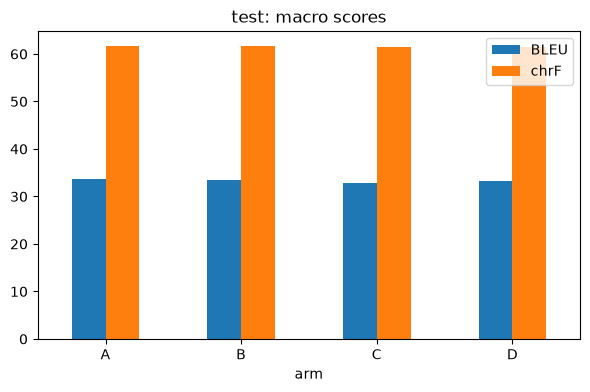

In [4]:
rows = []
for arm, report in reports.items():
    for pair in ("en-de", "en-fr"):
        pair_report = report["pairs"][pair]
        score = pair_report if arm in "AB" else pair_report["postedited"]
        rows.append({"arm": arm, "pair": pair, "N": pair_report["num_examples"],
                     "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    pair_rows = rows[-2:]
    rows.append({"arm": arm, "pair": "macro", "N": sum(r["N"] for r in pair_rows),
                 "BLEU": sum(r["BLEU"] for r in pair_rows) / 2,
                 "chrF": sum(r["chrF"] for r in pair_rows) / 2})
score_table = pd.DataFrame(rows, columns=["arm", "pair", "N", "BLEU", "chrF"])
if score_table.empty:
    print("Predictions and metrics for the chosen split are pending.")
else:
    display(score_table.round(3))
    macro = score_table[score_table["pair"] == "macro"].set_index("arm")
    display(macro[["BLEU", "chrF"]].plot.bar(rot=0, figsize=(7, 4), title=f"{SPLIT}: macro scores").figure)
    plt.close("all")


## Paired changes and qualitative examples

Compare translations for the **same** rows. Sentence-level chrF identifies candidates for manual inspection; it does not prove that a model resolved a pronoun or improved discourse. Review the source, preceding source and both translations before writing such claims in the report.


In [5]:
from sacrebleu.metrics import CHRF
chrf_metric = CHRF()
reference = truth["tgt"].tolist()
comparisons = {"context B − A": ("A", "B"), "LLM C − A": ("A", "C"),
               "LLM D − B": ("B", "D"), "context D − C": ("C", "D")}
summary = []
example_tables = {}
for name, (before, after) in comparisons.items():
    if before not in predictions or after not in predictions:
        continue
    old, new = predictions[before].tolist(), predictions[after].tolist()
    delta = [chrf_metric.sentence_score(b, [ref]).score -
             chrf_metric.sentence_score(a, [ref]).score
             for a, b, ref in zip(old, new, reference)]
    review = truth[KEYS + ["previous_src", "src", "tgt"]].copy()
    review[f"prediction_{before}"] = old
    review[f"prediction_{after}"] = new
    review["delta_sentence_chrF"] = delta
    example_tables[name] = review
    summary.append({"comparison": name, "changed": sum(a != b for a, b in zip(old, new)),
                    "helped": sum(d > 1e-9 for d in delta), "hurt": sum(d < -1e-9 for d in delta),
                    "tied": sum(abs(d) <= 1e-9 for d in delta),
                    "mean_sentence_chrF_delta": sum(delta) / len(delta)})
if summary:
    display(pd.DataFrame(summary).round(3))
    for name, table in example_tables.items():
        print(f"{name} — five largest positive changes")
        display(table.nlargest(5, "delta_sentence_chrF"))
        print(f"{name} — five largest negative changes")
        display(table.nsmallest(5, "delta_sentence_chrF"))
else:
    print("At least two complete arms are needed for paired examples.")


,comparison,changed,helped,hurt,tied,mean_sentence_chrF_delta
0,context B − A,774,384,380,736,0.025
1,LLM C − A,1230,603,615,282,-0.319
2,LLM D − B,806,394,392,714,-0.297
3,context D − C,1116,582,529,389,0.047


context B − A — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
78,en-de,en/ep-09-05-07-010.xml,142,156,Greenland has around twice the population of G...,Denmark gave 8% of its seats to 50 000 people.,Dänemark gab 8% seiner Sitze an 50 000 Menschen.,Dänemark hat 8% seiner Sitze für 50 000 Person...,Dänemark hat 8 % seiner Sitze an 50 000 Mensch...,29.819578
1290,en-de,en/ep-96-09-19.xml,2085,2173,The waterways represented the main cultural an...,The Mediterranean is Europe's link with Africa...,Das Mittelmeer ist Europas Verbindung zu Afrik...,Der Mittelmeerraum ist die Verbindung Europas ...,Das Mittelmeer ist Europas Verbindung zu Afrik...,28.254005
118,en-de,en/ep-08-01-15-010-02.xml,18,21,"Mr Hannan, to my knowledge, all votes which ha...",Therefore the Rules have been complied with me...,Folglich wurde die Geschäftsordnung akribisch ...,Deshalb wurden die Regeln sorgfältig eingehalten.,Daher wurden die Geschäftsordnungen sorgfältig...,25.163166
62,en-de,en/ep-08-07-07-014.xml,3,3,"The final draft agenda for this part-session, ...",The following amendments have been requested t...,Zu diesem Entwurf wurden folgende Änderungen b...,Folgende Änderungsanträge wurden an diesen Ent...,Zu diesem Entwurf wurden folgende Änderungsant...,22.851978
64,en-de,en/ep-06-05-18.xml,859,942,The tens of thousands who have been sent into ...,I now expect the Tibetan refugee centre and th...,"Ich rechne jetzt damit, dass auch das Flüchtli...",Ich erwarte nun die Wiedereröffnung des Tibete...,"Ich erwarte nun, dass das tibetische Flüchtlin...",19.083181


context B − A — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_A,prediction_B,delta_sentence_chrF
1029,en-de,en/ep-04-07-20.xml,161,164,Even though all the opinion polls show that Eu...,This is one of Parliament ’ s foremost tasks.,Das ist eine der wichtigsten Aufgaben für das ...,Das ist eine der wichtigsten Aufgaben des Parl...,Das ist eine der Hauptaufgaben des Parlaments.,-24.891832
910,en-de,en/ep-00-03-02.xml,306,319,"Hence, the relevance of your second question o...",The procedure for verifying the origin of prod...,Das Verfahren zur Überprüfung des Ursprungs de...,Das Verfahren zur Überprüfung des Ursprungs vo...,Mit dem Verfahren zur Herkunftskontrolle könne...,-23.704779
718,en-de,en/ep-97-10-22.xml,3081,3049,"Mr President, this evening we are discussing a...","Previously, additives were called foreign ingr...",Früher hießen Zusatzstoffe Fremdstoffe.,Zuvor hießen Zusatzstoffe ausländische Inhalts...,Zuvor wurden Zusätze als Fremdstoffe bezeichnet.,-21.783271
999,en-de,en/ep-02-05-13.xml,1362,1459,"However, for this to become a reality, we need...",What I am deeply concerned about is the lack o...,Sehr große Sorgen bereitet mir der Mangel an G...,"Was mich sehr beunruhigt, ist das Fehlen von G...","Was mich sehr beunruhigt, ist das Fehlen von G...",-19.207485
37,en-de,en/ep-11-02-03-009.xml,1695,1722,"It is necessary for the EU criteria to be met,...",There is an urgent need to make an effort to r...,"Es ist dringend erforderlich, Anstrengungen zu...","Es ist dringend erforderlich, Anstrengungen zu...","Es besteht dringende Notwendigkeit, die Abfall...",-18.878311


LLM C − A — five largest positive changes


... (7 outputs left out)

context D − C — five largest positive changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
361,en-fr,en/ep-07-06-06-014.xml,59,59,on behalf of the PPE-DE Group. - (LT) First of...,Tomorrow the European Parliament will vote on ...,"Demain, le Parlement européen votera une résol...",Demorgen wird der Europäische Parlamentstag di...,"Demain, le Parlement européen votera une résol...",71.307733
1444,en-de,en/ep-11-02-03-009.xml,1545,1575,In fact it adds another level of bureaucracy t...,There will be confusion about who is responsib...,"Es wird Verwirrung darüber geben, wer wofür ve...","Es wird Verwirrung geben, wer für was zuständi...","Es wird Verwirrung darüber geben, wer für was ...",40.782170
585,en-fr,en/ep-10-04-20-013.xml,145,147,"Instead, it will take the money of the British...",EUR 40 million would be better directed toward...,Il vaudrait mieux consacrer les 40 millions d'...,40 Millionen Euro würden besser in die Bau von...,40 millions d'euros seraient mieux dirigés ver...,29.432248
487,en-fr,en/ep-07-04-24-008.xml,141,137,The report still contains some very worrying a...,We cannot possibly accept those points and acc...,Nous ne pouvons pas accepter ces points et nou...,Nous ne pouvons absolument pas accepter ces po...,Nous ne pouvons pas accepter ces points et nou...,27.858641
257,en-de,en/ep-08-05-19-020.xml,137,141,"Mr President, I would like to thank the rappor...","Having said that, I would like to make three p...",Dennoch möchte ich drei Punkte ansprechen.,Daraufhin möchte ich drei Punkte aufweisen.,Darum möchte ich drei Punkte ansprechen.,25.313619


context D − C — five largest negative changes


,pair,doc_id,src_sent_id,tgt_sent_id,previous_src,src,tgt,prediction_C,prediction_D,delta_sentence_chrF
1291,en-fr,en/ep-02-05-13.xml,436,425,I suggest to you - and I hope this House will ...,It is not satisfactory.,Il n'est pas satisfaisant.,Cela n'est pas satisfaisant.,Cela ne satisfait pas.,-48.574643
36,en-fr,en/ep-02-04-24.xml,293,299,"Israel does, thank God, also have some very cr...","Yesterday in the Conference of Presidents, we ...","Nous nous sommes en effet entretenus hier, au ...","Hier, lors de la Conférence des présidents, no...","Hier, bei der Konferenz der Präsidenten, haben...",-32.416334
47,en-fr,en/ep-07-04-25-002.xml,170,186,About the death penalty or the International C...,About Kyoto or GMOs?,Sur Kyoto ou les OGM ?,Kyoto ou les OGM ?,À propos de Kyoto ou des OGM ?,-32.397381
741,en-de,en/ep-97-10-22.xml,2083,2037,One of these has always been for us that goods...,That has always been the basic understanding o...,Das war immer das Credo unserer Lebensmittelge...,Das war schon immer das Grundverständnis unser...,Das ist seit jeher das Grundverständnis unsere...,-30.914877
1216,en-fr,en/ep-10-03-10-008.xml,144,159,I wonder whether they would have preferred it ...,Would that have been a proportionate response?,Cette réaction aurait -elle été proportionnée ?,Cette réponse aurait-elle été proportionnée ?,Cela aurait-il été une réponse proportionnée ?,-27.525576


## COMET

Read saved reference-based COMET results for A/B/C/D on the selected split. Small descriptive mean differences do not by themselves establish statistical significance or a causal context effect.


In [6]:
comet_path = PROJECT_ROOT / "outputs" / "metrics" / f"comet_{SPLIT}_scaled_v3_metrics.json"
if comet_path.is_file():
    comet_report = json.loads(comet_path.read_text(encoding="utf-8"))
    assert comet_report.get("dataset") == "scaled_v3"
    assert comet_report.get("split") == SPLIT
    assert comet_report["inputs"]["dataset"]["sha256"] == actual_hash
    comet_rows = []
    for arm, details in comet_report["arms"].items():
        for pair, metrics in details["pairs"].items():
            comet_rows.append({"arm": arm, "pair": pair, "COMET": metrics["comet_mean"]})
        comet_rows.append({"arm": arm, "pair": "macro",
                           "COMET": details["macro_average_comet"]})
    display(pd.DataFrame(comet_rows).round(4))
    display(pd.DataFrame([{"comparison": name, "COMET delta": value["macro_comet_delta"]}
                          for name, value in comet_report["comparisons"].items()]).round(4))
else:
    print(f"COMET pending: {comet_path.name}")


,arm,pair,COMET
0,A,en-de,0.8674
1,A,en-fr,0.8725
2,A,macro,0.8700
3,B,en-de,0.8663
4,B,en-fr,0.8727
5,B,macro,0.8695
6,C,en-de,0.8666
7,C,en-fr,0.8743
8,C,macro,0.8704
9,D,en-de,0.8681


,comparison,COMET delta
0,context_without_llm,-0.0005
1,llm_sentence,0.0004
2,llm_context,0.0027
3,context_with_llm,0.0018


## Decoding ablation: Top-k and Top-p

Sampling was evaluated on **validation only**. The beam setting was frozen before the v3 test run. A positive COMET change with falling BLEU/chrF is reported as mixed evidence. The Qwen reranker does not see the gold reference.


In [7]:
if SPLIT == 'validation':
    decoding_root = PROJECT_ROOT / 'outputs' / 'decoding' / 'scaled_v3'
    folders = {
        'Top-k': decoding_root / 'validation_top_k_k50_n3_t0p8_seed42',
        'Top-p': decoding_root / 'validation_top_p_p0p9_n3_t0p8_seed42',
    }
    decoding_rows = []
    for name, folder in folders.items():
        path = folder / 'metrics.json'
        if not path.is_file():
            print(f'Pending {name}: {path}')
            continue
        result = json.loads(path.read_text(encoding='utf-8'))
        assert result['config']['dataset_sha256'] == actual_hash
        assert result['config']['split'] == 'validation' and not result['smoke_test']
        for pair, values in result['pairs'].items():
            decoding_rows.append({'method': name, 'pair': pair, 'N': values['num_examples'],
                                  'changed': values['changed'],
                                  'beam BLEU': values['beam_bleu'],
                                  'selected BLEU': values['reranked_bleu'],
                                  'beam chrF': values['beam_chrf'],
                                  'selected chrF': values['reranked_chrf']})
    if decoding_rows:
        display(pd.DataFrame(decoding_rows).round(3))
    comet_sampling_path = decoding_root / 'validation_comet_comparison' / 'metrics.json'
    if comet_sampling_path.is_file():
        sampling_comet = json.loads(comet_sampling_path.read_text(encoding='utf-8'))
        assert sampling_comet['provenance']['dataset'] == actual_hash
        comet_rows = []
        for method, value in sampling_comet['summary'].items():
            for pair, item in value['pairs'].items():
                comet_rows.append({'method': method, 'pair': pair, 'COMET': item['comet_mean'],
                                   'delta vs beam': item['mean_delta_vs_beam']})
            comet_rows.append({'method': method, 'pair': 'macro', 'COMET': value['macro_comet'],
                               'delta vs beam': value['macro_delta_vs_beam']})
        display(pd.DataFrame(comet_rows).round(4))
    else:
        print('Sampling COMET pending: run scripts/evaluate_decoding_comet.py')
else:
    print('Sampling ablation was selected on validation; the test split is not loaded here.')


Sampling ablation was selected on validation; the test split is not loaded here.


## Interpretation

Read the per-pair rows before interpreting equal-pair macro averages. Differences between validation and test or between Europarl v2 and v3 are not controlled model comparisons across datasets. Blinded AI judgments are exploratory error analysis, not human evaluation. A preceding sentence may clarify a referent, but a score change alone does not prove that context caused the translation improvement.


## Balanced versus unweighted LoRA

These four models share the v3 dataset and evaluation split. The unweighted models are an ablation, kept separate from the A/B/C/D post-edit experiment. Check dataset hashes before comparing scores.


In [8]:
ABLATED = {
    "sentence_balanced": "sentence_lora_balanced_scaled_v3",
    "sentence_unweighted": "sentence_lora_unweighted_scaled_v3",
    "context_balanced": "context_lora_balanced_scaled_v3",
    "context_unweighted": "context_lora_unweighted_scaled_v3",
}
ablation_rows = []
for label, run in ABLATED.items():
    path = PROJECT_ROOT / "outputs" / "metrics" / f"{run}_{SPLIT}_metrics.json"
    if not path.is_file():
        print("Pending ablation metrics:", path.name)
        continue
    result = json.loads(path.read_text(encoding="utf-8"))
    assert result["split"] == SPLIT and result["dataset_sha256"] == actual_hash
    for pair in ("en-de", "en-fr"):
        score = result["pairs"][pair]
        ablation_rows.append({"model": label, "pair": pair,
                              "BLEU": score["sacrebleu"], "chrF": score["chrf"]})
    ablation_rows.append({"model": label, "pair": "macro",
                          "BLEU": result["macro_average_sacrebleu"],
                          "chrF": result["macro_average_chrf"]})
if ablation_rows:
    display(pd.DataFrame(ablation_rows).round(3))


,model,pair,BLEU,chrF
0,sentence_balanced,en-de,29.194,59.010
1,sentence_balanced,en-fr,38.017,64.506
2,sentence_balanced,macro,33.606,61.758
3,sentence_unweighted,en-de,28.989,58.905
4,sentence_unweighted,en-fr,38.042,64.424
5,sentence_unweighted,macro,33.516,61.664
6,context_balanced,en-de,28.698,58.768
7,context_balanced,en-fr,38.325,64.606
8,context_balanced,macro,33.512,61.687
9,context_unweighted,en-de,28.751,58.746


## Blinded error review (AI-assisted)

Rows compare changed predictions, including separately selected COMET extremes. Only the random cue/non-cue rows are exploratory samples of changed outputs. These labels were produced by AI and must not be called human judgments.


In [9]:
if SPLIT == "validation":
    review_path = PROJECT_ROOT / "outputs/analysis/abcd_validation_scaled_v3/manual_review/ai_review_summary.json"
    if review_path.is_file():
        manual = json.loads(review_path.read_text(encoding="utf-8"))
        assert manual["dataset"] == "scaled_v3" and manual["split"] == "validation"
        comparison_rows = []
        for comparison, subsets in manual["comparisons"].items():
            for pair in ("en-de", "en-fr", "both"):
                values = subsets["random"][pair]
                comparison_rows.append({"comparison": comparison, "pair": pair,
                                        "N changed sampled": values["n"],
                                        "after better": values["meaning"]["after"],
                                        "before better": values["meaning"]["before"],
                                        "tie": values["meaning"]["tie"]})
        display(pd.DataFrame(comparison_rows))
    else:
        print("AI review summary pending:", review_path)
else:
    print("Manual review is validation-only; no test labels were used to select models.")


Manual review is validation-only; no test labels were used to select models.
